# Does Coinbase lead Kraken?

*Price discovery between two bitcoin exchanges, measured second by second over 20 days. The
checks behind it are in the [appendix](appendix.ipynb).*

## Where a price is made

Bitcoin trades on hundreds of exchanges at once, around the clock, and none of them is its
home. In contrast, shares in a company have one: the exchange that lists them. When Hasbrouck
(1995) measured where the prices of the Dow Jones stocks were set, at a time when they also
traded on several regional exchanges, he found that most of it happened at the New York Stock
Exchange, where they were listed, and that the other exchanges mostly followed.

Bitcoin has neither a listing exchange nor a closing bell, so when something changes what it is
worth, such as a large order or a piece of news, there is no obvious place for its price to
change first. It has to change everywhere, and it cannot change everywhere at once: someone
trades first, on some exchange, and the others catch up.

Economists call the way a market arrives at a new price *price discovery*, and asking where it
happens is asking which exchange's price the others follow. The answer matters not just to
academics, but to anyone who uses a bitcoin price. A trader who knows which exchange moves
first can read the others' next move from it. And if one exchange leads, a benchmark that
averages several exchanges, as the reference rates behind bitcoin futures and funds do, is
partly averaging one price with delayed copies of it.

## Two exchanges, one bitcoin

We study two exchanges, Coinbase and Kraken, which we will also call *venues*, the general word
for any place where trading happens. Both trade bitcoin against US dollars, so their prices
compare directly, with no exchange rate in between, and a bitcoin bought on one venue is
identical to a bitcoin bought on the other. By the [law of one
price](https://en.wikipedia.org/wiki/Law_of_one_price), then, the two should trade at the same
price. If they did not, anyone could buy on the cheaper venue, sell on the more expensive one
and lock in a risk-free profit, and that buying and selling, called *arbitrage*, would push the
two prices back together.

Arbitrage does close the gap, but not instantly and not for free. Makarov and Schoar (2020)
found large and persistent price gaps between crypto exchanges in different countries, and much
smaller ones between exchanges in the same country, where there is no currency to convert and
no capital control to get around. Even there the gaps do not vanish: US dollars are
interchangeable, but their location still matters. Money in a Kraken account cannot buy bitcoin
on Coinbase until it has been withdrawn and sent across, by bank transfer or on the blockchain,
and neither is quick. So an arbitrageur has to keep money waiting on both venues in advance,
and where moving it across a border is slow or restricted, gaps can last.

Coinbase and Kraken are both large American venues trading in the same currency, so we should
expect their prices to stay close, and they do. But close is not identical, and the two prices
need not be equal partners. When news arrives, one venue's price can move first and the other's
a moment later, and when the two drift apart, one of them can do most of the moving back. So
the question is not whether the two prices agree, since over minutes they do, but which one
moves and which one follows in the seconds when they disagree. When one venue's price
consistently moves first and the other's follows, we say that the first venue *leads*.

Why a venue would lead is a separate question. It might come from the traders who use Coinbase,
bringing their news there first, or from something about the venue itself that holds whoever is
trading, and we return to the question at the end.

## Three ways of looking

We recorded both venues' order books for 20 days. We start by simply watching the two prices
for a few minutes, to see what there is to explain, and then ask the question three ways. Each
way has a blind spot, but the blind spots differ, so the answer does not rest on any one of
them.

- **Following the jumps.** We take every moment one price jumped and average what both prices
  did around it. This is the most direct look and needs no model, but it sees only the large
  moves, and when both prices jump in the same second it cannot say which went first until we
  open that second up.
- **Can Coinbase forecast Kraken?** If Kraken follows Coinbase, Coinbase's order book should
  predict Kraken's next few seconds better than Kraken's book predicts Coinbase's, so we train
  a forecast each way and score both on days they never saw. This uses every second rather than
  only the jumps, and scoring on unseen days keeps it honest, but the forecast is a black box:
  it shows that Coinbase's book knows something about Kraken's next move, not how much of the
  price each venue sets.
- **Who closes the gap?** The standard tool of the price-discovery literature, the one
  Hasbrouck used, models how each price responds when the two drift apart and turns that into a
  single number: the share of lasting price change that starts at each venue. It is simple and
  transparent, but on one-second bars it cannot see inside a second either, so it gives a range
  rather than a point.

At the end we turn from *when* to *why*, and ask what might make Coinbase lead.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import json

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from research.runs import read_oos
from research.validation import confidence_intervals

# The figures' colours, type and labelling helpers, shared with the appendix.
from charts import (AXIS, COINBASE, GRID, INK, INK2, KRAKEN, LABEL_BOX, MUTED, SURFACE,
                    apart, categories, day_labels, headline, name_series, note, signed)

DATA = next(p for p in (Path("data"), Path("../data")) if p.exists())
real = json.loads((DATA / "record_real.json").read_text(encoding="utf-8"))
prices = pl.read_parquet(DATA / "prices.parquet").sort("ts_ns")

## Watching them move

To compare the two prices we first need to say what a venue's price is, because at any moment
an exchange shows not one price but many. Each exchange keeps an *order book*, a list of every
standing offer to buy or sell bitcoin at the price each trader named. The highest offer to buy
is the *bid*, the lowest offer to sell is the *ask*, and the gap between them is the *spread*.
Halfway between the bid and the ask is the *mid-price*, and from here on, that is what we mean
by a venue's price.

We sampled both books once a second over the 20 days and kept only the seconds in which both
books were current, so that we never compare a live price with a stale one.

In [2]:
ts = prices["ts_ns"].to_numpy()
day = prices["date"].to_numpy()
mids = prices.select(["coinbase_mid", "kraken_mid"]).to_numpy()

# A second follows on from the row before it only if no second was dropped in between.
follows = np.r_[False, (np.diff(ts) == 1_000_000_000) & (day[1:] == day[:-1])]
changed = (np.diff(mids, axis=0) != 0)[follows[1:]]
gap = mids[:, 0] - mids[:, 1]
gap_bp = (np.log(mids[:, 0]) - np.log(mids[:, 1])) * 1e4

print(f"{len(prices):,} seconds with both books current, over {len(set(day))} days")
print(f"Coinbase's price changes in {changed[:, 0].mean():.0%} of seconds, "
      f"Kraken's in {changed[:, 1].mean():.0%}")
print(f"Coinbase averages ${-gap.mean():.2f} ({-gap_bp.mean():.2f} bp) below Kraken")

# The text below quotes these.
assert f"{len(prices):,}" == "1,529,334"
assert f"{changed[:, 0].mean():.0%} {changed[:, 1].mean():.0%}" == "33% 13%"
assert f"{-gap.mean():.2f} {-gap_bp.mean():.2f}" == "2.29 0.38"

1,529,334 seconds with both books current, over 20 days
Coinbase's price changes in 33% of seconds, Kraken's in 13%
Coinbase averages $2.29 (0.38 bp) below Kraken


Before averaging anything, it helps to see what the raw prices look like. Here are three
minutes of them, drawn at random from the busiest tenth of minutes, measured by how far
Coinbase's price travelled, so that something is happening in each.

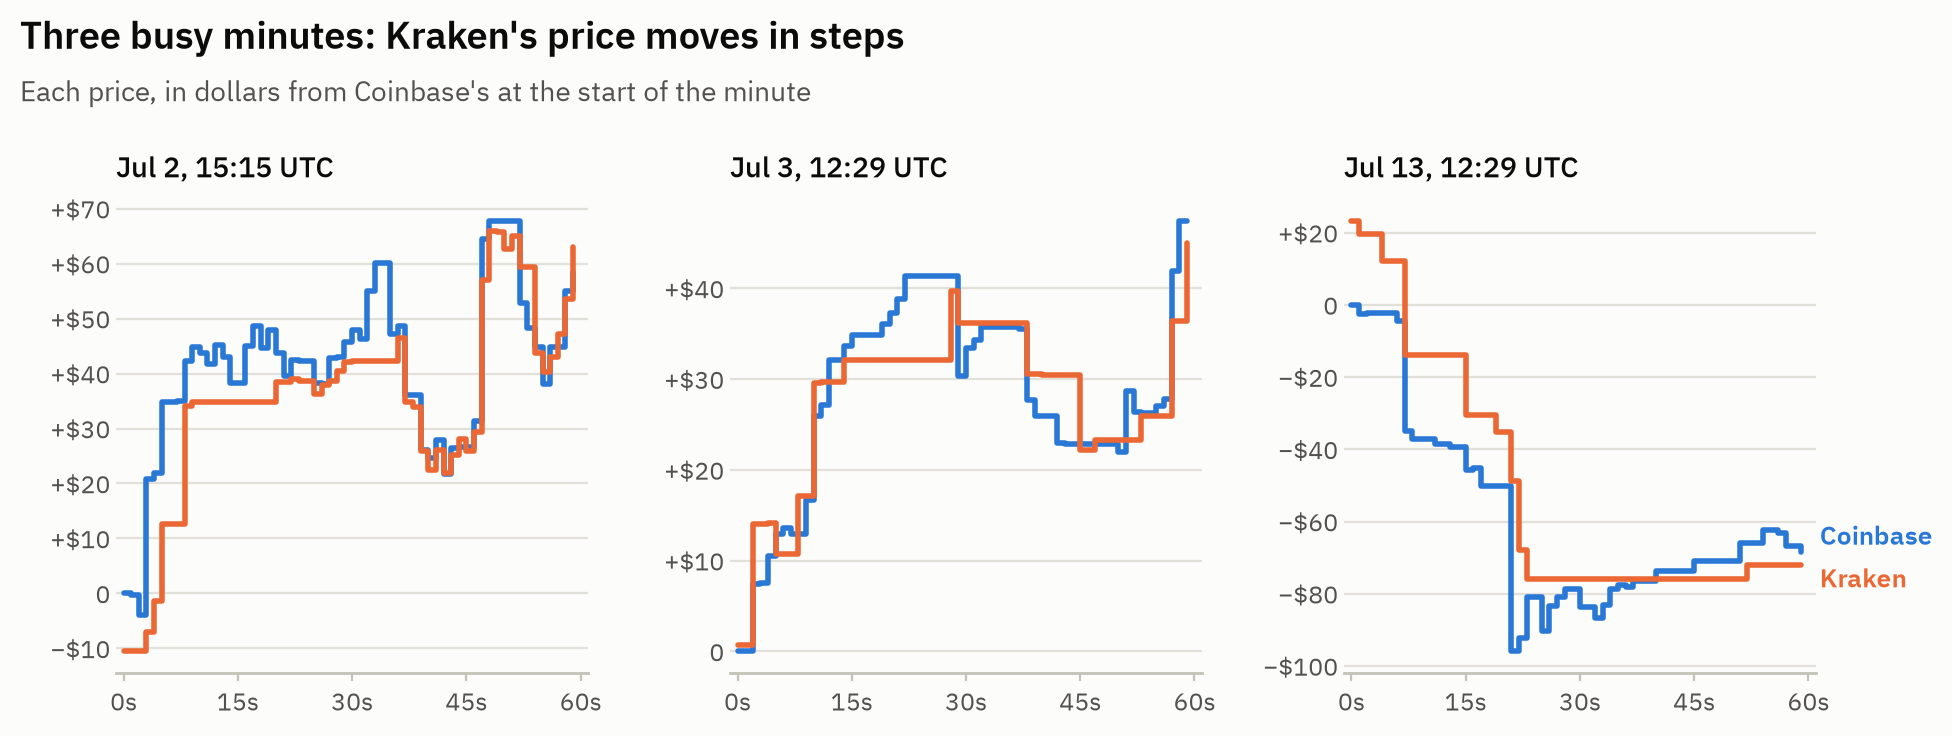

In [3]:
# Whole clock minutes only, so no panel has a missing second in it.
whole = (
    prices.with_columns(minute=pl.col("ts_ns") // 60_000_000_000)
    .filter(pl.len().over("minute") == 60)
)
travel = whole.group_by("minute", maintain_order=True).agg(
    move=(pl.col("coinbase_mid").last() / pl.col("coinbase_mid").first()).log().abs() * 1e4
)
busiest = travel.filter(pl.col("move") > pl.col("move").quantile(0.9))["minute"].to_numpy()
picked = np.sort(np.random.default_rng(1).choice(busiest, 3, replace=False))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.7))
for ax, minute in zip(axes, picked):
    w = whole.filter(pl.col("minute") == minute)
    second = (w["ts_ns"].to_numpy() - w["ts_ns"][0]) / 1e9
    start = w["coinbase_mid"][0]
    for venue, colour in (("coinbase", COINBASE), ("kraken", KRAKEN)):
        ax.step(second, w[f"{venue}_mid"] - start, where="post", color=colour, lw=2)
    when = datetime.fromtimestamp(w["ts_ns"][0] / 1e9, tz=timezone.utc)
    ax.set_title(f"{when:%b} {when.day}, {when:%H:%M} UTC")
    ax.set_xticks([0, 15, 30, 45, 60], ["0s", "15s", "30s", "45s", "60s"])
    ax.set_xlim(-1, 61)
    ax.yaxis.set_major_formatter(signed(prefix="$"))
    ax.grid(axis="y")
# The venues named once, where the last minute's lines end.
ends = (w[-1, "coinbase_mid"] - start, w[-1, "kraken_mid"] - start)
low, high = axes[-1].get_ylim()
for y, name, colour in zip(apart(ends, 0.09 * (high - low)), ("Coinbase", "Kraken"),
                           (COINBASE, KRAKEN)):
    name_series(axes[-1], 61.5, y, name, colour)
headline(fig, "Three busy minutes: Kraken's price moves in steps",
         "Each price, in dollars from Coinbase's at the start of the minute",
         left=0.06, right=0.91, bottom=0.09, wspace=0.3)
plt.show()

Two things are visible straight away. The first is that the prices are not identical: across
the 20 days, Coinbase averages \$2.29, or 0.38 basis points, below Kraken. (A basis point is a
hundredth of a percent.) The second is that they do not move alike. Coinbase's price changes in
33% of seconds and Kraken's in only 13%, so Kraken's line is a staircase, flat for stretches
and then stepping, and its steps often come just after Coinbase has moved.

Often is not always, though: in the middle minute it is Kraken that steps first. Three minutes
are an anecdote, however carefully chosen, so the next section replaces them with an average
over every large move in the 20 days.

## Following the jumps

If one price follows the other, the clearest place to see it is around the large moves, because
a large move at one venue is an unmistakable event, which the other venue either echoes or does
not. So we line up every moment one venue's price jumped and average what both prices did
around it, which turns many untidy individual moves into one typical move.

A *jump* here is a move of at least 2 basis points in a single second. For each jump we measure
both prices from where they stood the second before, flip the falling jumps so that every jump
points up, and average from ten seconds before the jump to fifteen seconds after it.

In [4]:
JUMP_BP, BEFORE, AFTER = 2.0, 10, 15
offsets = np.arange(-BEFORE, AFTER + 1)
logp = np.log(mids) * 1e4               # in basis points, so differences are moves in bp
stretch = np.cumsum(~follows)           # rows sharing a number are one unbroken run


def around_jumps(venue):
    """Both prices around every jump at one venue, from where each stood the second
    before, flipped so the jump points up. Returns the jump rows and their paths."""
    move = np.r_[np.nan, np.diff(logp[:, venue])]
    at = np.flatnonzero(follows & (np.abs(move) >= JUMP_BP))
    at = at[(at >= BEFORE) & (at + AFTER < len(logp))]
    at = at[stretch[at - BEFORE] == stretch[at + AFTER]]  # no missing second in the window
    paths = logp[at[:, None] + offsets] - logp[at - 1][:, None, :]
    return at, paths * np.sign(move[at])[:, None, None]


now, later = BEFORE, BEFORE + 10  # where the jump second, and ten seconds on, sit in a path
jumps = {"Coinbase": around_jumps(0), "Kraken": around_jumps(1)}
for venue, (at, _) in jumps.items():
    print(f"{venue:9s} {len(at):,} jumps of at least {JUMP_BP:g} bp")
print(f"{JUMP_BP:g} bp at the median price, ${np.median(mids[:, 0]):,.0f}, "
      f"is ${np.median(mids[:, 0]) * JUMP_BP / 1e4:.0f}")

at, paths = jumps["Coinbase"]
mean = paths.mean(axis=0)
by_day = [paths[day[at] == d][:, later].mean(axis=0) for d in sorted(set(day))]
covered = [k / c for c, k in by_day]
print(f"\nwhen Coinbase jumps, in the same second: Coinbase {mean[now, 0]:.2f} bp, "
      f"Kraken {mean[now, 1]:.2f} bp")
print(f"ten seconds on, Kraken has covered {mean[later, 1] / mean[later, 0]:.0%} "
      f"of Coinbase's move ({min(covered):.0%} to {max(covered):.0%} by day)")

at, paths = jumps["Kraken"]
mean = paths.mean(axis=0)
run_up = [-paths[day[at] == d][:, 0, 0].mean() for d in sorted(set(day))]
print(f"\nwhen Kraken jumps, from ten seconds before to the second before: "
      f"Coinbase rose {-mean[0, 0]:.2f} bp, Kraken {-mean[0, 1]:.2f} bp")
print(f"  Coinbase's run-up by day: {min(run_up):.2f} to {max(run_up):.2f} bp")
print(f"in the same second: Kraken {mean[now, 1]:.2f} bp, Coinbase {mean[now, 0]:.2f} bp; "
      f"over the next ten, Coinbase {mean[later, 0] - mean[now, 0]:.2f} bp more")

# The text below quotes these.
c, k = jumps["Coinbase"][1].mean(axis=0), mean
assert f"{c[now, 0]:.2f} {c[now, 1]:.2f} {c[later, 1] / c[later, 0]:.0%}" == "3.07 1.50 91%"
assert f"{min(covered):.0%} {max(covered):.0%}" == "69% 96%"
assert f"{-k[0, 0]:.2f} {-k[0, 1]:.2f} {k[later, 0] - k[now, 0]:.2f}" == "2.20 0.74 0.29"
assert min(run_up) > 0

Coinbase  22,446 jumps of at least 2 bp
Kraken    23,835 jumps of at least 2 bp
2 bp at the median price, $62,780, is $13



when Coinbase jumps, in the same second: Coinbase 3.07 bp, Kraken 1.50 bp
ten seconds on, Kraken has covered 91% of Coinbase's move (69% to 96% by day)



when Kraken jumps, from ten seconds before to the second before: Coinbase rose 2.20 bp, Kraken 0.74 bp
  Coinbase's run-up by day: 0.93 to 2.59 bp
in the same second: Kraken 3.04 bp, Coinbase 1.61 bp; over the next ten, Coinbase 0.29 bp more


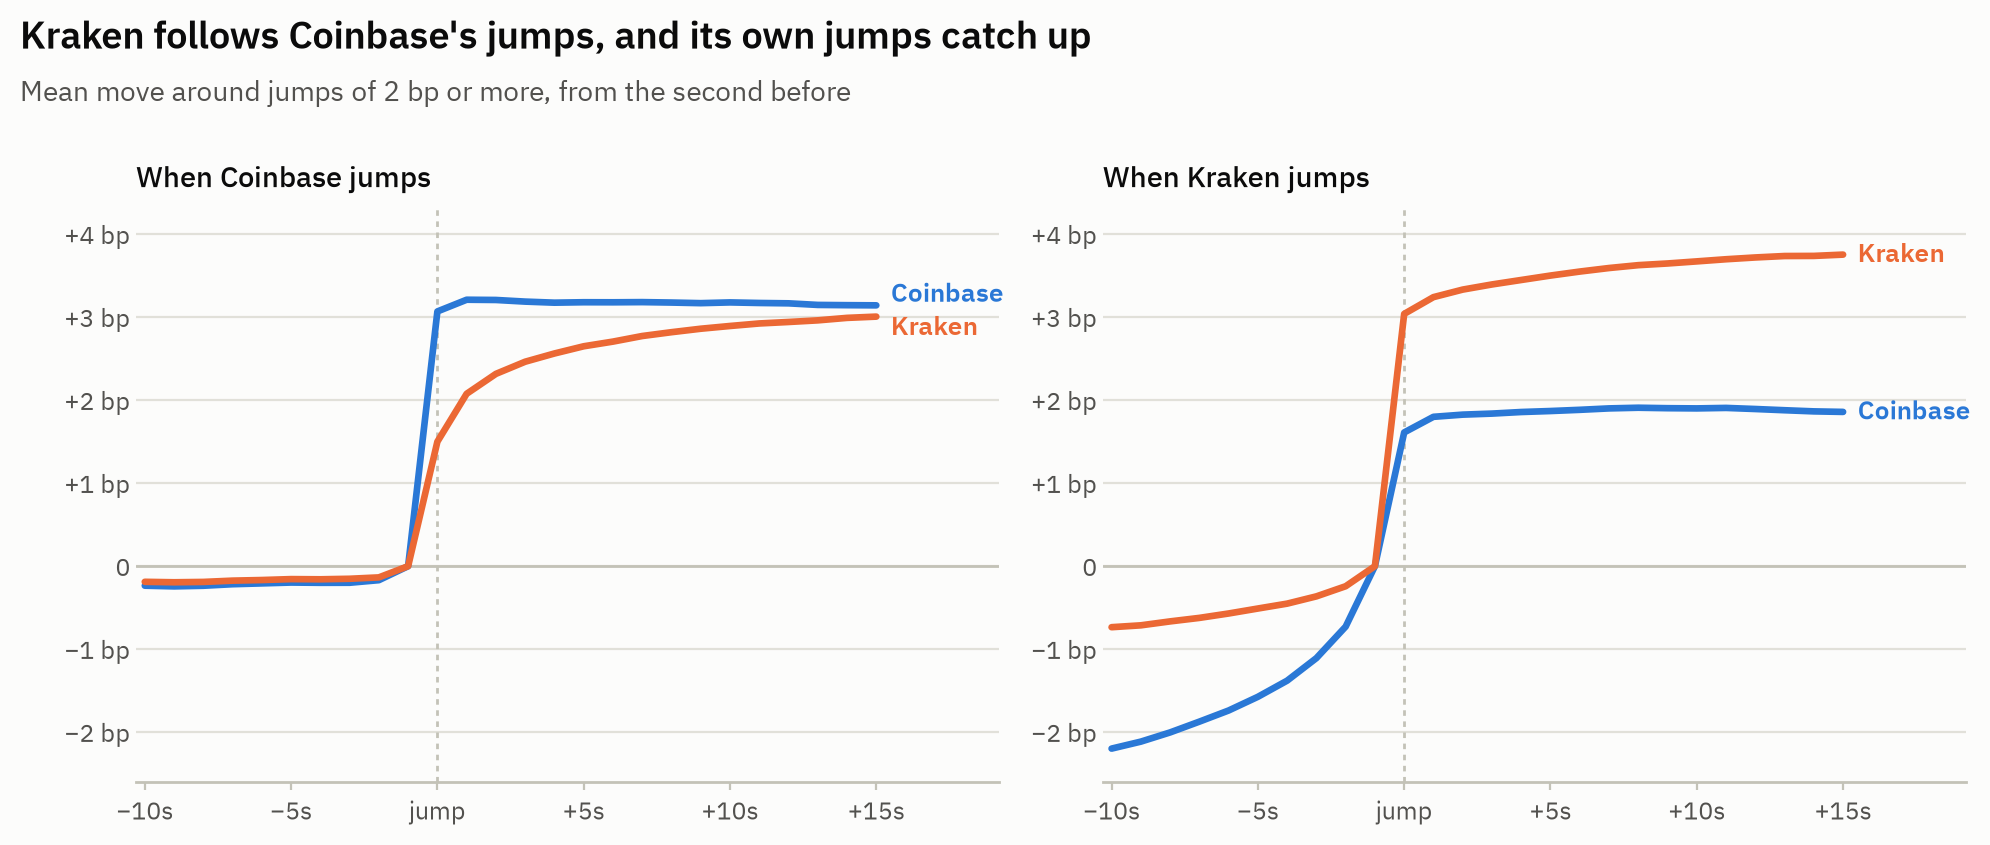

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharey=True)
for ax, (jumper, (_, paths)) in zip(axes, jumps.items()):
    mean = paths.mean(axis=0)
    ax.axvline(0, color=AXIS, lw=1, ls=(0, (2, 2)), zorder=1)
    ax.axhline(0, color=AXIS, lw=1, zorder=1)
    for i, colour in enumerate((COINBASE, KRAKEN)):
        ax.plot(offsets, mean[:, i], color=colour, lw=2.4, zorder=4)
    # Named where the lines end, pushed apart when they finish too close to read both.
    for y, venue, colour in zip(apart(mean[-1], 0.4), ("Coinbase", "Kraken"), (COINBASE, KRAKEN)):
        name_series(ax, AFTER + 0.5, y, venue, colour)
    ax.set_title(f"When {jumper} jumps")
    ax.set_xticks([-10, -5, 0, 5, 10, 15], ["−10s", "−5s", "jump", "+5s", "+10s", "+15s"])
    ax.set_xlim(-BEFORE - 0.3, AFTER + 4.2)
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(axis="y")
axes[0].set_ylim(-2.6, 4.3)
axes[0].yaxis.set_major_formatter(signed("bp"))
headline(fig, "Kraken follows Coinbase's jumps, and its own jumps catch up",
         f"Mean move around jumps of {JUMP_BP:g} bp or more, from the second before",
         top=1.05, left=0.07, right=0.985, bottom=0.09, wspace=0.12)
plt.show()

The two panels are not mirror images, and the difference between them is the result.

When Coinbase jumps (left), little has happened beforehand at either venue. Kraken moves 1.50
bp in the same second, against Coinbase's 3.07, and then it keeps moving, so that ten seconds
on it has covered 91% of Coinbase's move. Day by day that figure runs from 69% to 96%, so this
is not the work of a few unusual days.

When Kraken jumps (right), by contrast, the action starts before the jump. From ten seconds
before it to the second before it, Coinbase rose 2.20 bp in the direction Kraken is about to
go, against 0.74 bp for Kraken itself, and that run-up is there on every one of the 20 days.
Once Kraken has jumped, Coinbase barely moves, adding only 0.29 bp over the next ten seconds.
On average, then, a Kraken jump is not news arriving at Kraken but Kraken catching up with a
move Coinbase has already made.

Both panels share one blind spot, however. In the jump second itself both prices move, and
one-second bars cannot say which of them moved first inside that second. For that we need the
books themselves, which record far finer times.

### Inside the jump second

Every book update carries the moment it reached our capture machine, to well under a
millisecond, so the jump second can be opened up. We read both books again at that resolution
around every jump. This time, rather than lining the jumps up on whole seconds, we line them up
on the instant the jumping venue's price first stood 1 basis point from where it was when the
second began, which we call its *crossing*. Then we average both prices every 10 milliseconds
around it, each measured from where it stood a second before the crossing.

In [6]:
paths = pl.read_parquet(DATA / "jump_paths.parquet")
crossings = pl.read_parquet(DATA / "jump_crossings.parquet")


def around_crossings(jumper, clock="arrival"):
    """Both prices around every jump at one venue on the 10 ms grid, in bp from where each
    stood a second before the crossing: `jumper` for the venue that jumped, `other` for the
    other. The file holds sums by day, so averaging over days is a sum."""
    return (
        paths.filter((pl.col("leader") == jumper) & (pl.col("clock") == clock))
        .group_by("ms").agg(pl.col("n", "leader_sum", "other_sum").sum()).sort("ms")
        .with_columns(jumper=pl.col("leader_sum") / pl.col("n"),
                      other=pl.col("other_sum") / pl.col("n"))
    )


def made(a):
    """The share of its move to five seconds after the crossing that the other venue had
    made at the crossing."""
    at = dict(a.select("ms", "other").iter_rows())
    return at[0] / at[5000]


def both_jumped(clock="arrival"):
    """The seconds in which both prices jumped the same way, with how many ms Coinbase's
    crossing came before Kraken's."""
    cross = f"cross_{clock}_ms"
    return (crossings.filter(pl.col("leader") == "coinbase")
            .join(crossings.filter(pl.col("leader") == "kraken"), on=["date", "ts_ns", "sign"])
            .drop_nulls([cross, f"{cross}_right"])
            .with_columns(ahead=pl.col(f"{cross}_right") - pl.col(cross)))


crossing = {jumper: around_crossings(jumper) for jumper in ("coinbase", "kraken")}
print(f"{crossing['coinbase']['n'][0]:,} Coinbase jumps and {crossing['kraken']['n'][0]:,} "
      "Kraken jumps, each lined up on its crossing")
print(f"\nwhen Coinbase's price crosses, Kraken's has made {made(crossing['coinbase']):.0%} of its "
      "move to five seconds on")
print(f"when Kraken's price crosses, Coinbase's has made {made(crossing['kraken']):.0%} of its move")

pairs = both_jumped()
by_day = pairs.group_by("date").agg(first=(pl.col("ahead") > 0).mean())["first"]
print(f"\n{pairs.height:,} seconds in which both prices jumped the same way: Coinbase's crossed "
      f"first in {(pairs['ahead'] > 0).mean():.0%} of them, a median {pairs['ahead'].median():.0f} ms "
      f"ahead, and in {by_day.min():.0%} to {by_day.max():.0%} of them by day")

stamps = {jumper: around_crossings(jumper, "exchange") for jumper in crossing}
stamp_pairs = both_jumped("exchange")
print(f"\non the exchanges' own stamps: {made(stamps['coinbase']):.0%} and "
      f"{made(stamps['kraken']):.0%}, and Coinbase's crossed first in "
      f"{(stamp_pairs['ahead'] > 0).mean():.0%} of {stamp_pairs.height:,} seconds, a median "
      f"{stamp_pairs['ahead'].median():.0f} ms ahead")

# The text below quotes these.
assert f"{made(crossing['coinbase']):.0%} {made(crossing['kraken']):.0%} {pairs.height:,} " \
       f"{(pairs['ahead'] > 0).mean():.0%} {pairs['ahead'].median():.0f} {by_day.min():.0%} " \
       f"{by_day.max():.0%}" == "16% 58% 7,438 69% 63 61% 84%"
assert f"{made(stamps['coinbase']):.0%} {made(stamps['kraken']):.0%} " \
       f"{(stamp_pairs['ahead'] > 0).mean():.0%} {stamp_pairs.height:,} " \
       f"{stamp_pairs['ahead'].median():.0f}" == "25% 49% 54% 7,270 14"

22,446 Coinbase jumps and 23,835 Kraken jumps, each lined up on its crossing

when Coinbase's price crosses, Kraken's has made 16% of its move to five seconds on
when Kraken's price crosses, Coinbase's has made 58% of its move



7,438 seconds in which both prices jumped the same way: Coinbase's crossed first in 69% of them, a median 63 ms ahead, and in 61% to 84% of them by day

on the exchanges' own stamps: 25% and 49%, and Coinbase's crossed first in 54% of 7,270 seconds, a median 14 ms ahead


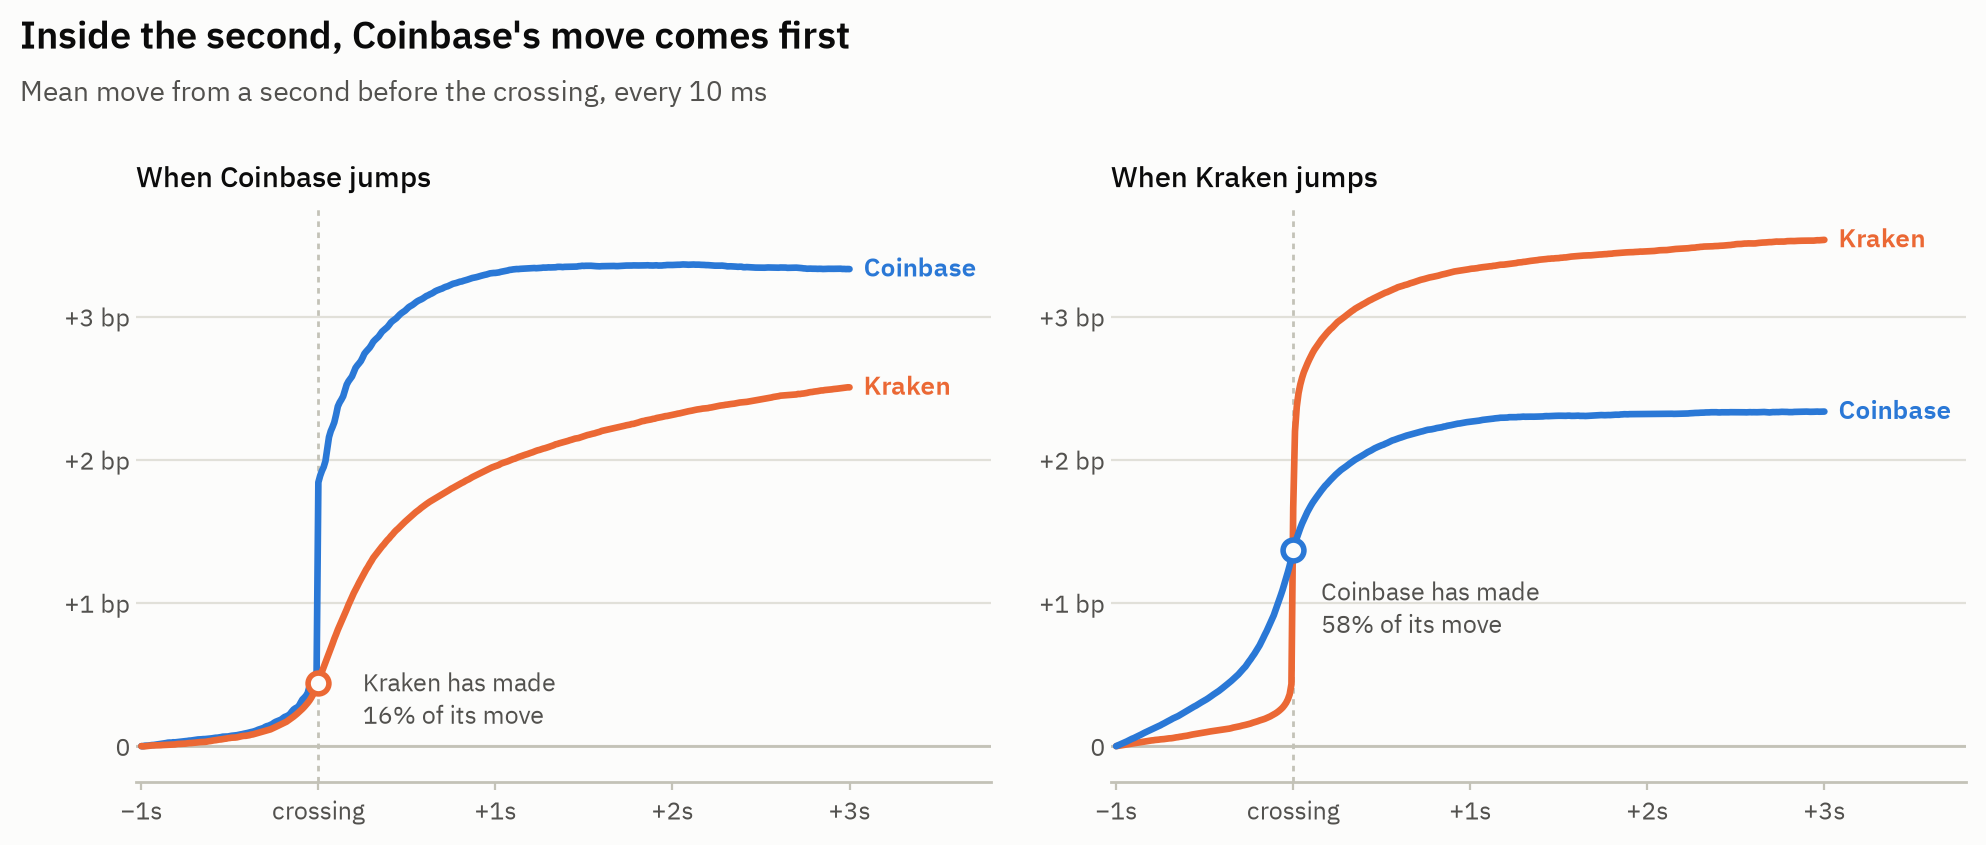

In [7]:
names = {"coinbase": ("Coinbase", COINBASE), "kraken": ("Kraken", KRAKEN)}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharey=True)
for ax, (jumper, a) in zip(axes, crossing.items()):
    other = "kraken" if jumper == "coinbase" else "coinbase"
    shown = a.filter(pl.col("ms").is_between(-1000, 3000))
    ax.axvline(0, color=AXIS, lw=1, ls=(0, (2, 2)), zorder=1)
    ax.axhline(0, color=AXIS, lw=1, zorder=1)
    for venue, column in ((jumper, "jumper"), (other, "other")):
        ax.plot(shown["ms"], shown[column], color=names[venue][1], lw=2.4, zorder=4)
    ends = [shown[column][-1] for column in ("jumper", "other")]
    for y, venue in zip(apart(ends, 0.3), (jumper, other)):
        name_series(ax, 3080, y, *names[venue])
    # Where the other venue stood at the crossing.
    y = a.filter(pl.col("ms") == 0)["other"].item()
    ax.plot([0], [y], "o", color=names[other][1], mfc=SURFACE, mew=2, ms=7.5, zorder=5)
    ax.annotate(f"{names[other][0]} has made\n{made(a):.0%} of its move", (0, y),
                xytext=(16, -18) if jumper == "coinbase" else (10, -30), textcoords="offset points",
                va="bottom" if jumper == "coinbase" else "baseline", fontsize=9, color=INK2)
    ax.set_title(f"When {names[jumper][0]} jumps")
    ax.set_xticks([-1000, 0, 1000, 2000, 3000], ["−1s", "crossing", "+1s", "+2s", "+3s"])
    ax.set_xlim(-1030, 3800)
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(axis="y")
axes[0].yaxis.set_major_locator(mpl.ticker.MultipleLocator(1))
axes[0].yaxis.set_major_formatter(signed("bp"))
axes[0].set_ylim(-0.25, 3.75)
headline(fig, "Inside the second, Coinbase's move comes first",
         "Mean move from a second before the crossing, every 10 ms",
         top=1.05, left=0.07, right=0.985, bottom=0.09, wspace=0.14)
plt.show()

Reading these panels takes one piece of care. Lining the jumps up on one venue's crossing gives
that venue a head start, because at the crossing it has just moved by definition, while the
other venue was not chosen for moving at all. Since that happens in both panels, the other
venue would trail in each of them even if the two prices moved in perfect step, so neither
panel on its own says which moved first; only the comparison between them does. If the two
prices moved together, the panels would be mirror images.

They are not. When Coinbase's price crosses (left), Kraken's has made only 16% of the move it
will have made five seconds later. When Kraken's crosses (right), Coinbase's has been rising
through the whole second before and has already made 58% of its move. The head start is the
same in both panels, so the difference between the two is Coinbase's lead.

The seconds in which both prices jumped give neither venue a head start, since both were chosen
for moving, and so they offer a cleaner comparison. In the 7,438 seconds in which both jumped
the same way, Coinbase's price crossed first in 69%, a median 63 ms before Kraken's, and it did
so in 61% to 84% of them depending on the day. What one-second bars show as the two prices
moving together, then, mostly comes in order, Coinbase's first, by tens of milliseconds.

One more check is needed, because these times are when each update reached us rather than when
it happened at the exchange, and the two exchanges' messages take different times to arrive.
The exchanges' own timestamps are the clock least favourable to Coinbase, as the appendix
shows, and on them the order is closer, though it still runs the same way: Coinbase's price
crosses first in 54% of the 7,270 seconds in which both jumped, a median 14 ms ahead, and
Kraken has made 25% of its move at Coinbase's crossing, against Coinbase's 49% at Kraken's.

## Can Coinbase forecast Kraken?

The jump charts look only at the large moves, and they describe what happened rather than
predict anything. A forecast does both things they cannot: it uses every second, large move or
not, and it has to predict what it has not yet seen. If Kraken follows Coinbase, then what is
happening at Coinbase now should say something about where Kraken's price goes next. The idea
is Clive Granger's (1969), and economists call it [Granger
causality](https://en.wikipedia.org/wiki/Granger_causality), though it is a test of forecasting
rather than of cause: if one series leads another, its past should help forecast the other's
future. So we can test it directly, by building a forecast and scoring it on days it never saw.

The forecast predicts how far Kraken's price moves over the next five seconds, and it is
allowed to look only at Coinbase: Coinbase's spread, how much is on offer near the best prices
on each side, how lopsided the recent buying and selling has been, and how its price has moved
lately. Nothing from Kraken goes in, so the forecast cannot simply extend Kraken's own recent
moves, and whatever it knows about Kraken's future it must have learned from Coinbase.

The model is gradient boosting, which fits many small decision trees, each correcting the
errors of the ones before it. We use it rather than a straight-line regression because an order
book does not move a price in a straight line. The same burst of buying moves the price a long
way when little is on offer and hardly at all when the book is deep, and a tree can learn that
kind of interaction without our having to spell it out. The appendix runs linear regressions on
the same inputs alongside it: they score below the tree in every round, and in the round whose
test days span the longest gap in the recording they do worse than predicting no change at all.

To know whether the forecast is any good we need something to beat, and we use the simplest
forecast there is, that the price will not move:

$$
R^2 = 1 - \frac{\sum_t (y_t - \hat{y}_t)^2}{\sum_t y_t^2}
$$

Here $y_t$ is Kraken's actual five-second move and $\hat{y}_t$ is the forecast, so the score is
zero for a forecast no better than predicting no change, one for a perfect forecast, and
negative for one that does worse than standing still.

The forecast is scored the way it would have had to be used, which means it is trained only on
earlier days and tested on the days after them, never on a day it has already seen; in the
jargon, it is tested *walk-forward* and *out of sample*. We do this in four rounds that between
them test 12 of the 20 days. The range given with each score comes from resampling whole test
days, so it reflects how much the result varies from one day to the next. Finally, to have
something to compare the score with, we run the whole thing again in the other direction,
forecasting Coinbase from Kraken alone, with nothing else changed.

In [8]:
forecasts = {
    "Coinbase to Kraken": read_oos(pl.read_parquet(DATA / "oos_real.parquet"))["gbt"],
    "Kraken to Coinbase": read_oos(pl.read_parquet(DATA / "oos_reverse.parquet"))["gbt"],
}
scores = {direction: confidence_intervals(o) for direction, o in forecasts.items()}
print(f"{len(real['folds'])} rounds, {real['n_test_dates']} test days\n")
for direction, s in scores.items():
    (r2, low, high), hit = s["r2_vs_zero"], s["hit_rate"][0]
    print(f"{direction}: R2 {r2:.3f} [{low:.3f}, {high:.3f}], "
          f"direction right on {hit:.0%} of moves")
forward, backward = (scores[d]["r2_vs_zero"][0] for d in forecasts)
print(f"the forward R2 is {forward / backward:.1f} times the reverse")
y = forecasts["Coinbase to Kraken"].y
print(f"always guessing 'up' would be right on {(y[y != 0] > 0).mean():.0%} of Kraken's moves")


def r2_by_day(o):
    """R2 against no change, one test day at a time."""
    return {d: 1 - ((o.y - o.pred)[o.dates == d] ** 2).sum() / (o.y[o.dates == d] ** 2).sum()
            for d in np.unique(o.dates)}


by_day = {direction: r2_by_day(o) for direction, o in forecasts.items()}
test_days = sorted(by_day["Coinbase to Kraken"])
ahead = [by_day["Coinbase to Kraken"][d] / by_day["Kraken to Coinbase"][d] for d in test_days]
print(f"\nforward ahead on {sum(a > 1 for a in ahead)} of {len(test_days)} test days, "
      f"by {min(ahead):.1f} to {max(ahead):.1f} times")

# The text below quotes these.
fwd, rev = scores["Coinbase to Kraken"], scores["Kraken to Coinbase"]
assert "{:.3f} {:.3f} {:.3f}".format(*fwd["r2_vs_zero"]) == "0.103 0.091 0.112"
assert "{:.3f} {:.3f} {:.3f}".format(*rev["r2_vs_zero"]) == "0.011 0.008 0.014"
assert f"{fwd['hit_rate'][0]:.0%} {rev['hit_rate'][0]:.0%} {forward / backward:.1f}" == "76% 58% 9.6"
assert f"{(y[y != 0] > 0).mean():.0%} {min(ahead):.1f}" == "51% 3.4" and min(ahead) > 1

4 rounds, 12 test days

Coinbase to Kraken: R2 0.103 [0.091, 0.112], direction right on 76% of moves
Kraken to Coinbase: R2 0.011 [0.008, 0.014], direction right on 58% of moves
the forward R2 is 9.6 times the reverse
always guessing 'up' would be right on 51% of Kraken's moves



forward ahead on 12 of 12 test days, by 3.4 to 19.5 times


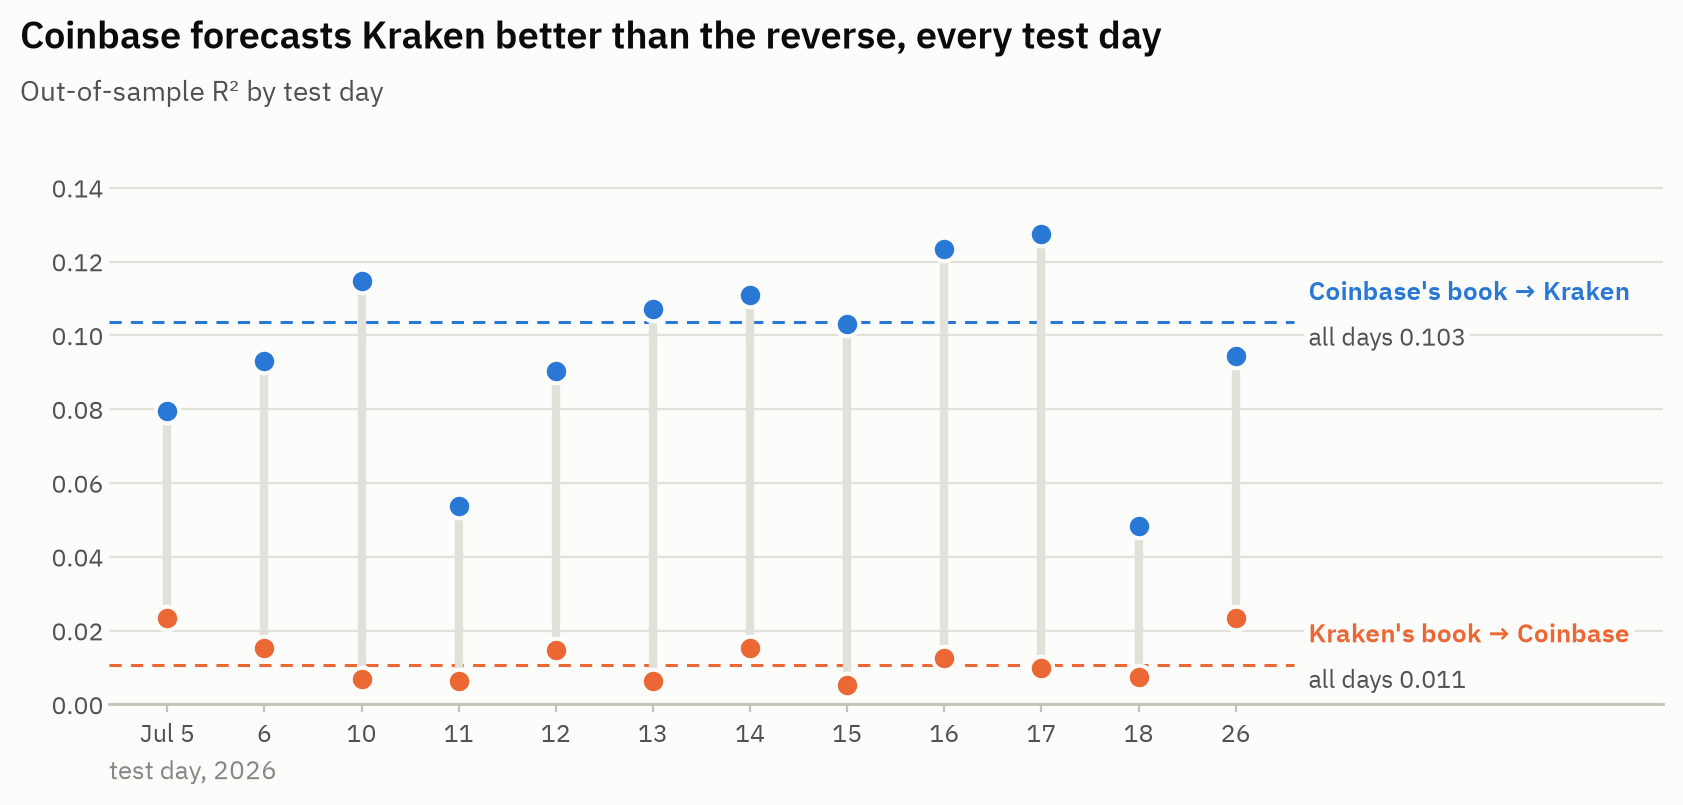

In [9]:
fig, ax = plt.subplots(figsize=(8.4, 4.1))
x = np.arange(len(test_days))
sources = (("Coinbase to Kraken", COINBASE, "Coinbase's book → Kraken"),
           ("Kraken to Coinbase", KRAKEN, "Kraken's book → Coinbase"))
ax.vlines(x, *([by_day[d][t] for t in test_days] for d, _, _ in sources), color=GRID, lw=3,
          zorder=2)
for direction, colour, label in sources:
    ax.plot(x, [by_day[direction][t] for t in test_days], "o", color=colour, ms=8.5,
            mec=SURFACE, mew=1.5, zorder=4)
    pooled = scores[direction]["r2_vs_zero"][0]
    # Stopped short of the right edge, so the labels can sit at its end.
    ax.hlines(pooled, -0.6, len(test_days) - 0.4, color=colour, lw=1.1, ls=(0, (4, 3)), zorder=1)
    name_series(ax, len(test_days) - 0.25, pooled + 0.0045, label, colour, va="bottom", bbox=LABEL_BOX)
    note(ax, len(test_days) - 0.25, pooled - 0.001, f"all days {pooled:.3f}", va="top",
         bbox=LABEL_BOX)
ax.set_xticks(x, day_labels(test_days))
ax.set_xlim(-0.6, len(test_days) + 3.4)
ax.set_ylim(0, 0.145)
ax.yaxis.set_major_formatter("{x:.2f}")
ax.set_xlabel("test day, 2026", loc="left")
ax.grid(axis="y")
headline(fig, "Coinbase forecasts Kraken better than the reverse, every test day",
         "Out-of-sample R² by test day", top=0.85, left=0.065, right=0.99, bottom=0.14)
plt.show()

Coinbase's book forecasts Kraken's next five seconds with an R² of 0.103, in a range of 0.091
to 0.112, which means it accounts for about a tenth of the squared movement in Kraken's price,
on days the model never trained on. To put it more plainly, if we count only the five-second
stretches in which Kraken's price moved, the forecast got the direction right 76% of the time,
where always guessing "up" would have managed 51%. None of this is a trading result, since the
forecast is of the mid-price and ignores fees, the spread and whether an order would have been
filled.

Run the other way round, Kraken's book forecasts Coinbase with an R² of only 0.011 (0.008 to
0.014), and it gets the direction right on 58% of moves. The forward direction is therefore 9.6
times the reverse overall, and it is ahead on every one of the 12 test days, by at least 3.4
times. Coinbase's book knows a good deal about Kraken's next few seconds, while Kraken's knows
little about Coinbase's.

## Who closes the gap?

The jump charts and the forecast agree that Coinbase's price moves first and Kraken's catches
up. Neither, though, says how much of the price is set at each venue, and for that question the
price-discovery literature has its own tool. It is far simpler than a gradient-boosted
forecast, it is the tool Hasbrouck used for the New York Stock Exchange, and it answers with a
share: how much of the lasting change in the price starts at each venue.

It starts from the tie between the two prices. Arbitrage keeps them close but not equal, so
they drift apart for a moment and then come back together, and when they part, one of them, or
both, must move to close the gap. Which one does is what this section measures.

To make that precise, write $p^C_t$ and $p^K_t$ for the log of each venue's mid-price at second
$t$ (logs, so that a gap between them is a percentage rather than a dollar amount), and
$\Delta p_t$ for how far a price moved in that second. In words, the model says that each
venue's move in a given second is made of three parts: a pull toward the other venue's price,
in proportion to how far apart the two were a second earlier; an echo of both prices' moves
over the last ten seconds; and a *shock*, the part of the move, large or small, that neither of
those explains. Written out, with one equation per venue:

$$
\Delta p^K_t = \mu_K + a_K\,(p^C_{t-1} - p^K_{t-1}) + \sum_{k=1}^{10}\big(b_k\,\Delta p^C_{t-k} + c_k\,\Delta p^K_{t-k}\big) + \varepsilon^K_t
$$

$$
\Delta p^C_t = \mu_C + a_C\,(p^K_{t-1} - p^C_{t-1}) + \sum_{k=1}^{10}\big(b'_k\,\Delta p^C_{t-k} + c'_k\,\Delta p^K_{t-k}\big) + \varepsilon^C_t
$$

The pulls, $a_K$ and $a_C$, are the terms we care about. The sum over the last ten seconds is
there to absorb momentum, so that none of it gets credited to the pull, and the constant $\mu$
lets the gap's usual level be something other than zero. That matters here because Coinbase
averages 0.38 basis points below Kraken, and a pull should be measured toward where the gap
normally sits. Each equation measures the gap from its own venue's side, so $a_K$ and $a_C$ are
the same kind of number: the share of the gap to the other venue that a venue closes in the
next second. A venue that sets the price should have $a$ near zero, because it has nothing to
catch up to, while a venue that follows should have $a$ clearly above zero.

The pair of equations is what economists call a [vector error-correction
model](https://en.wikipedia.org/wiki/Error_correction_model), or VECM, the standard tool for
two prices that wander but stay tied together. We keep to plainer words, but the literature's
are the ones to look up: prices tied together in this way are
[*cointegrated*](https://en.wikipedia.org/wiki/Cointegration), the gap is the *error-correction
term*, each pull is an *adjustment coefficient*, and the shocks are *innovations*. Fitting the
model takes nothing more than least squares, so we fit it ourselves, separately on each of the
20 days. We fit it on one-second bars, because the jump charts showed Kraken catching up within
seconds and anything coarser would blur the order of events. And we use only the seconds whose
previous ten were all kept, because across a stretch of dropped seconds the two prices can be
minutes apart, and the move between them is not a one-second move.

In [10]:
def fit_day(p, whole, lags=10):
    """Least squares for one day's pair of equations. `p` is that day's log prices, one
    row per second, Coinbase then Kraken, and `whole` marks the rows that follow on from
    the row before with no second dropped. Returns each venue's pull and the shocks."""
    dp = np.diff(p, axis=0)                    # each move, from one row to the next
    gap = p[:-1, 0] - p[:-1, 1]                # Coinbase minus Kraken, before each move
    # A move is used only if it and the ten before it each span exactly one second.
    stretch = np.cumsum(~whole)
    t = np.arange(lags, len(dp))
    t = t[stretch[t - lags] == stretch[t + 1]]
    X = np.column_stack([gap[t], *(dp[t - k] for k in range(1, lags + 1)), np.ones(len(t))])
    coef, *_ = np.linalg.lstsq(X, dp[t], rcond=None)
    shocks = dp[t] - X @ coef
    # One set of regressors serves both equations. Its gap is Coinbase minus Kraken, which
    # is Kraken's side of it; Coinbase's own side is the negative, so its pull flips sign.
    return np.array([-coef[0, 0], coef[0, 1]]), shocks


def by_day(step=1):
    """Each day's log prices on bars `step` seconds apart, and which bars follow on."""
    for (d,), g in prices.group_by(["date"], maintain_order=True):
        g = g.filter(pl.col("ts_ns") % (step * 1_000_000_000) == 0)
        whole = np.r_[False, np.diff(g["ts_ns"].to_numpy()) == step * 1_000_000_000]
        yield d, np.log(g.select(["coinbase_mid", "kraken_mid"]).to_numpy()), whole


fits = {d: fit_day(p, whole) for d, p, whole in by_day()}
dates = [d[5:] for d in fits]
pulls = np.array([a for a, _ in fits.values()])
closes = {"Coinbase": pulls[:, 0], "Kraken": pulls[:, 1]}
used = sum(len(e) for _, e in fits.values())
moves = sum(len(p) - 11 for _, p, _ in by_day())
print(f"fitted {len(fits)} days on {used:,} one-second moves, leaving out the "
      f"{moves - used:,} ({1 - used / moves:.1%}) with a dropped second in their last ten\n")

for venue, a in closes.items():
    print(f"{venue:9s} closes {a.mean():.2%} of the gap a second on average "
          f"(daily range {a.min():.2%} to {a.max():.2%})")
ratio = closes["Kraken"].mean() / closes["Coinbase"].mean()
print(f"\nKraken pulls {ratio:.0f} times as hard as Coinbase, on average")
print(f"Kraken's pull is above zero on {(closes['Kraken'] > 0).sum()} of {len(fits)} days")
print(f"Coinbase's is below zero on {(closes['Coinbase'] < 0).sum()} of {len(fits)} days")

# The text below quotes these. If the data changes, this fails before the text goes stale.
assert f"{closes['Kraken'].mean():.2%} {closes['Coinbase'].mean():.2%} {ratio:.0f}" == "4.55% 0.27% 17"
assert f"{closes['Coinbase'].min():.2%}" == "-0.09%"
assert (closes["Kraken"] > 0).sum() == 20 and (closes["Coinbase"] < 0).sum() == 4

fitted 20 days on 1,490,818 one-second moves, leaving out the 38,296 (2.5%) with a dropped second in their last ten

Coinbase  closes 0.27% of the gap a second on average (daily range -0.09% to 1.26%)
Kraken    closes 4.55% of the gap a second on average (daily range 1.08% to 8.31%)

Kraken pulls 17 times as hard as Coinbase, on average
Kraken's pull is above zero on 20 of 20 days
Coinbase's is below zero on 4 of 20 days


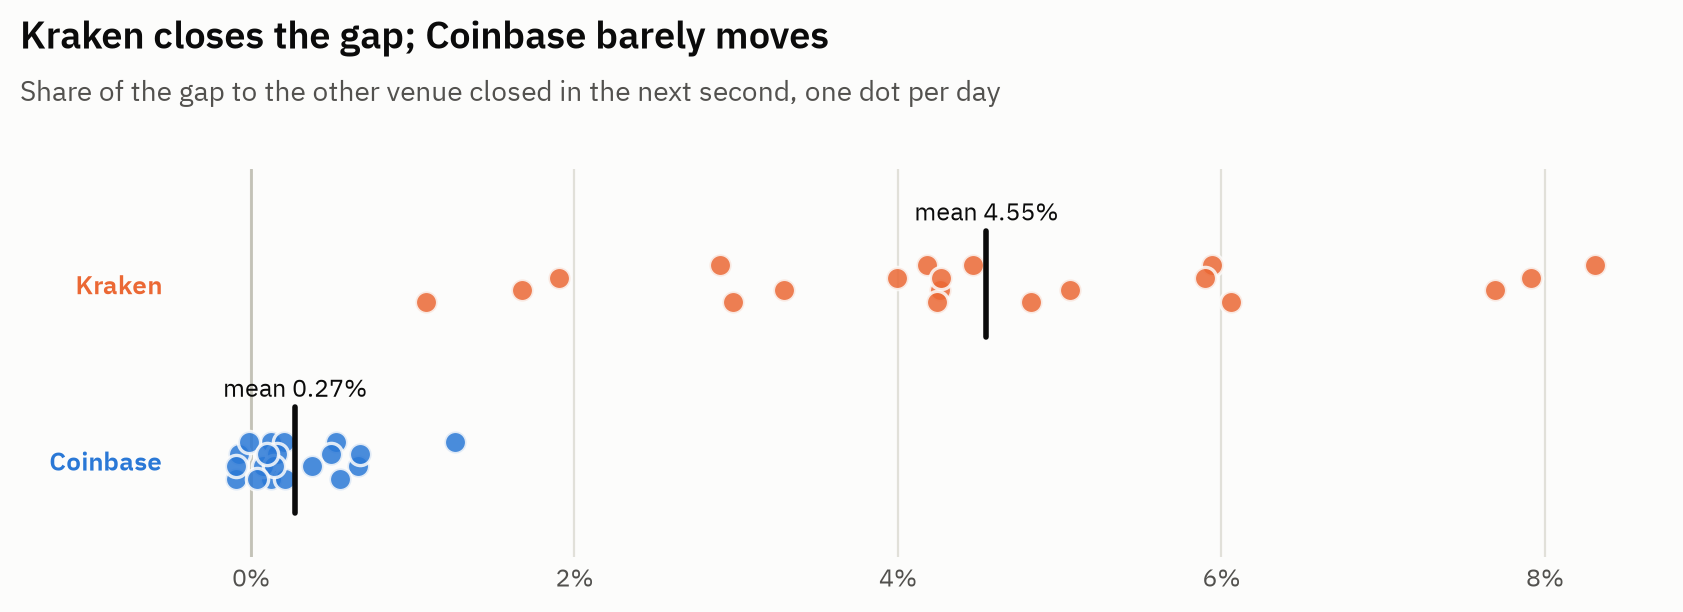

In [11]:
fig, ax = plt.subplots(figsize=(8.4, 3.1))
for row, (venue, colour) in enumerate([("Coinbase", COINBASE), ("Kraken", KRAKEN)]):
    a = closes[venue]
    # Spread the dots a little vertically, in rank order, so close days stay visible.
    lift = (np.argsort(np.argsort(a)) % 4 - 1.5) * 0.07
    ax.plot(a, row + lift, "o", color=colour, ms=8, alpha=0.85, mec=SURFACE, mew=1.2, zorder=4)
    ax.plot([a.mean()] * 2, [row - 0.3, row + 0.3], color=INK, lw=2, zorder=5)
    note(ax, a.mean(), row + 0.36, f"mean {a.mean():.2%}", ha="center", color=INK)
ax.axvline(0, color=AXIS, lw=1)
categories(ax, ["Coinbase", "Kraken"], [COINBASE, KRAKEN])
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_ylim(-0.55, 1.65)
headline(fig, "Kraken closes the gap; Coinbase barely moves",
         "Share of the gap to the other venue closed in the next second, one dot per day",
         top=0.85, left=0.1, right=0.99, bottom=0.1)
plt.show()

Kraken closes 4.55% of the gap each second on average, and its pull is above zero on all 20
days. Coinbase closes only 0.27%, so Kraken pulls 17 times as hard. Coinbase's pull is so close
to zero, in fact, that on 4 of the 20 days its estimate dips just below it, to -0.09% at the
lowest. When the two prices part, then, it is Kraken that moves to close the gap, while
Coinbase barely moves at all.

### Whose news sticks?

Knowing who closes the gap tells us which price is the anchor, but not yet how much of the
price each venue sets. Hasbrouck's *information share*, the standard measure in this
literature, goes one step further by asking whose news lasts.

The shocks, the $\varepsilon$ in the equations, are where news enters the two prices. Some are
undone within seconds, as when a price overshoots and comes back, while the rest permanently
move the price that both venues share, which Hasbrouck calls the *efficient price*. The
information share is the fraction of that permanent movement that started at each venue.

The two pulls are enough to say how much each shock counts, because a shock lasts only if the
other venue follows it. A shock at Coinbase lasts to the extent that Kraken chases it, and a
shock at Kraken to the extent that Coinbase does:

$$
\text{permanent move}_t \;\propto\; a_K\,\varepsilon^C_t + a_C\,\varepsilon^K_t
$$

If the two venues' shocks were unrelated, Coinbase's share would follow directly, with $\sigma$
for the typical size of each venue's shock:

$$
\text{IS}_C = \frac{a_K^2\,\sigma_C^2}{a_K^2\,\sigma_C^2 + a_C^2\,\sigma_K^2}
$$

They are not unrelated, though, and this is the blind spot from the jump charts again. On
one-second bars, when both books move inside the same second, the regression cannot say which
moved first, so that shared part of the shocks could belong to either venue. We therefore
compute the share twice, once crediting the shared part to Coinbase and once to Kraken, and
report the range between them, Hasbrouck's lower and upper *bounds*. The width of the range is
exactly how much the data cannot resolve, so a narrow range is a confident answer.

In [12]:
def coinbase_share(pulls, shocks):
    """Coinbase's information share as a (low, high) range, and how correlated the two
    venues' shocks were."""
    omega = np.cov(shocks, rowvar=False)
    weight = np.array([pulls[1], pulls[0]])    # Coinbase's shock counts by Kraken's pull
    total = weight @ omega @ weight
    shares = []
    for order in ([0, 1], [1, 0]):
        # The factor splits the two shocks into all of the first venue's, and only what
        # the second adds beyond it, so whichever venue goes first is credited the overlap.
        factor = np.linalg.cholesky(omega[np.ix_(order, order)])
        piece = (weight[order] @ factor) ** 2 / total
        shares.append(piece[order.index(0)])
    return sorted(shares), omega[0, 1] / np.sqrt(omega[0, 0] * omega[1, 1])


shares = [coinbase_share(a, e) for a, e in fits.values()]
bounds = np.array([b for b, _ in shares])
corr = np.array([c for _, c in shares])
widest = int(bounds[:, 0].argmin())

# The same fit on bars thirty seconds apart instead.
shares_30 = [coinbase_share(*fit_day(p, whole)) for _, p, whole in by_day(30)]
bounds_30 = np.array([b for b, _ in shares_30])
corr_30 = np.array([c for _, c in shares_30])

print(f"Coinbase's information share, one-second bars, {len(fits)} days")
print(f"  range averaged over the days  [{bounds[:, 0].mean():.3f}, {bounds[:, 1].mean():.3f}]")
print(f"  widest day                    {dates[widest]}: "
      f"[{bounds[widest, 0]:.3f}, {bounds[widest, 1]:.3f}]")
print(f"  shock correlation             {corr.mean():.2f} on average, "
      f"{corr[widest]:.2f} on {dates[widest]}, the highest of any day")
print(f"\nthirty-second bars instead: range averaged over the days "
      f"[{bounds_30[:, 0].mean():.3f}, {bounds_30[:, 1].mean():.3f}], "
      f"shock correlation {corr_30.mean():.2f} on average")

# Quoted in the text below.
assert corr.argmax() == widest
assert f"[{bounds[:, 0].mean():.3f}, {bounds[:, 1].mean():.3f}]" == "[0.754, 0.997]"
assert f"{dates[widest]} [{bounds[widest, 0]:.3f}, {bounds[widest, 1]:.3f}]" == "06-29 [0.545, 0.992]"
assert f"{corr.mean():.2f} {corr[widest]:.2f}" == "0.46 0.61"
assert f"{bounds_30[:, 0].mean():.3f} {bounds_30[:, 1].mean():.3f} {corr_30.mean():.2f}" == \
    "0.237 0.983 0.89"

Coinbase's information share, one-second bars, 20 days
  range averaged over the days  [0.754, 0.997]
  widest day                    06-29: [0.545, 0.992]
  shock correlation             0.46 on average, 0.61 on 06-29, the highest of any day

thirty-second bars instead: range averaged over the days [0.237, 0.983], shock correlation 0.89 on average


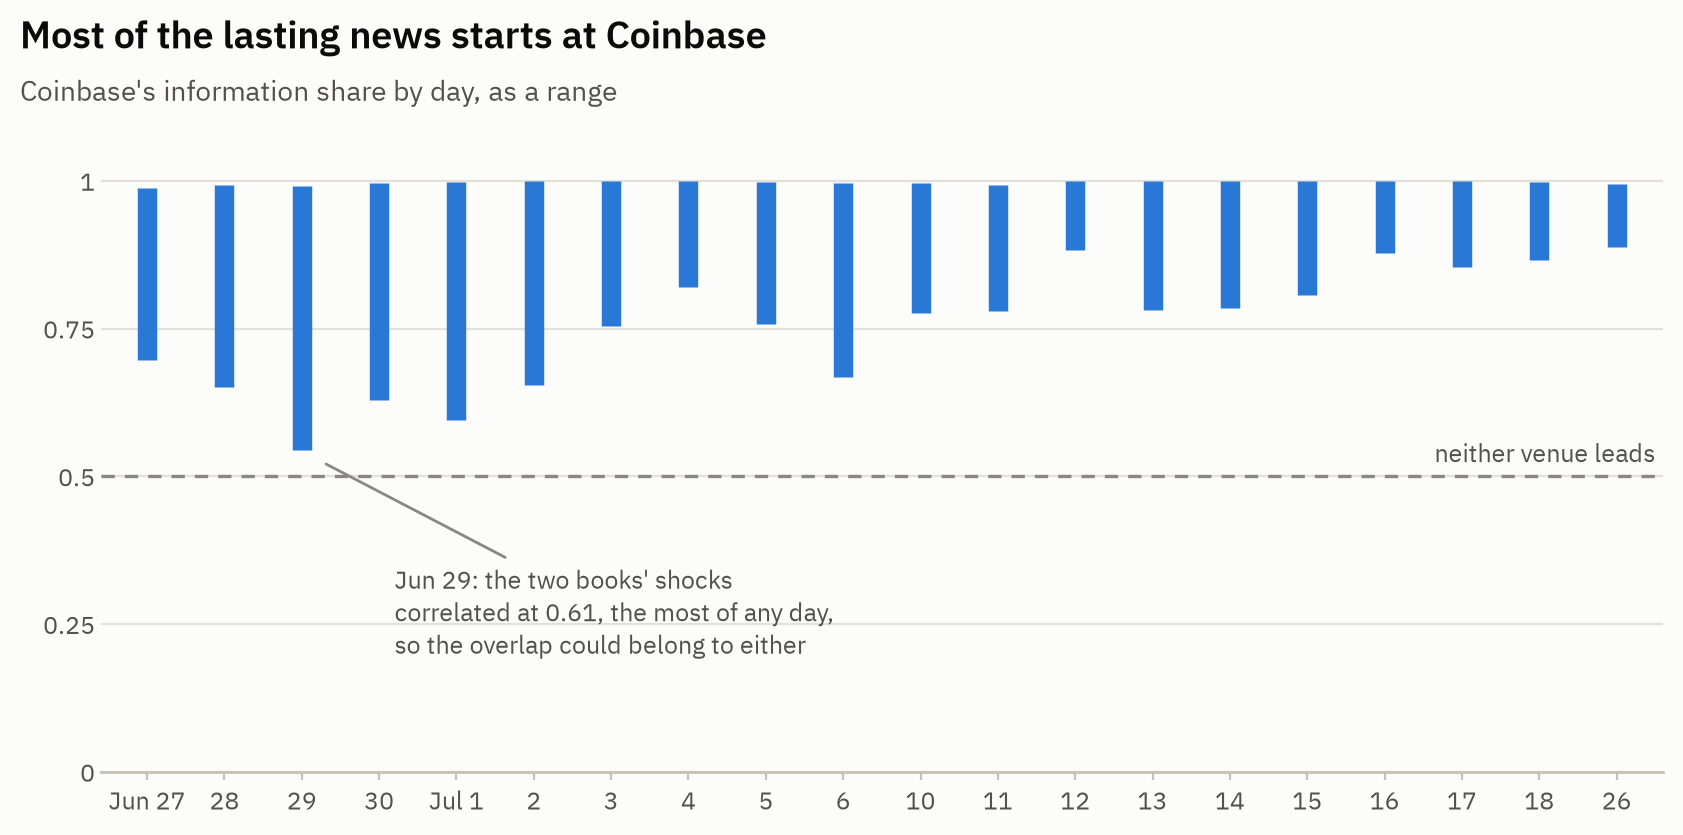

In [13]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
x = np.arange(len(fits))
for i, (low, high) in enumerate(bounds):
    ax.plot([i, i], [low, high], color=COINBASE, lw=7, solid_capstyle="butt", zorder=4)
ax.axhline(0.5, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=2)
note(ax, len(fits) - 0.5, 0.515, "neither venue leads", ha="right", va="bottom")
ax.annotate(f"{day_labels([list(fits)[widest]])[0]}: the two books' shocks\n"
            f"correlated at {corr[widest]:.2f}, the most of any day,\n"
            "so the overlap could belong to either",
            xy=(widest + 0.25, bounds[widest, 0] - 0.02), xytext=(widest + 1.2, 0.2),
            ha="left", fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_xticks(x, day_labels(list(fits)))
ax.set_xlim(-0.6, len(fits) - 0.4)
ax.set_ylim(0, 1.02)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "0.25", "0.5", "0.75", "1"])
ax.grid(axis="y")
headline(fig, "Most of the lasting news starts at Coinbase",
         "Coinbase's information share by day, as a range",
         top=0.85, left=0.06, right=0.99, bottom=0.08)
plt.show()

On a typical day the range sits far above one half, the line at which neither venue would lead,
and averaged over the 20 days it runs from 0.754 to 0.997. Even crediting every shared shock to
Kraken, then, most of the lasting change in the price starts at Coinbase.

The range is widest on the day the two venues' shocks overlapped most. On June 29 they
correlated at 0.61, against 0.46 on average, so more of each second's news landed on both books
at once and the data could not say where it started. Even so, the range that day runs from
0.545 to 0.992, so its lower end is still above one half.

These are one-second bars, and the answer depends on that, in just the way the jump charts
would lead us to expect. Kraken catches up within seconds, so if we sample every thirty seconds
instead, both venues have caught up with almost any news by the time we look. Their shocks then
correlate at 0.89 rather than 0.46, the shared part that the data cannot assign swallows most
of the range, and the range averaged over the days widens to 0.237 to 0.983. That does not mean
the lead disappears at thirty seconds, only that thirty-second bars are too coarse to see a
lead measured in seconds.

## Why might Coinbase lead?

Everything so far measures timing: Coinbase's price moves first and Kraken's follows. Why that
happens is a different kind of question, and the prices cannot settle it on their own, but they
can rule some answers out. The answers fall into two kinds, and the two predict different
things about the clock.

The first kind says that the lead belongs to particular traders. Some group with news to act
on, large American firms for instance, does its trading on Coinbase, so Coinbase's price moves
first while they are at work. If that is why Coinbase leads, the lead should rise and fall with
those traders' working day, and weaken in the hours when the market belongs to traders
elsewhere, some of whom will bring their news to Kraken first.

The second kind says that the lead belongs to the venue, whoever happens to be trading.
Coinbase is the busier market, its price changing in 33% of seconds against Kraken's 13%, and a
trader with something to act on, whether a large order to fill or a view to trade on, is most
likely to act where the most trading already happens, at any hour. The traders who post most of
the quotes on an exchange, its *market makers*, also often set them by watching a busier
exchange's price, so that when Coinbase's price moves, Kraken's quotes would be revised after
it, a fraction of a second later. Either way, Kraken should follow in the same way at every
hour, however busy the market and whoever is trading.

To tell the two kinds apart, we split each day into three eight-hour blocks of UTC time,
roughly the working days of Asia, Europe and the Americas, and split the days by whether the US
stock market was open. In each, we count how often Coinbase's price jumps and measure how much
of each jump Kraken has covered ten seconds later, exactly as in the jump charts.

In [14]:
from datetime import date

# 07-03 was a Friday, but US stock exchanges closed for Independence Day.
stocks_open = {d: date.fromisoformat(d).weekday() < 5 and d != "2026-07-03" for d in set(day)}
day0 = pl.col("date").str.to_date().cast(pl.Datetime("ns")).cast(pl.Int64)
tagged = prices.select(
    # The midnight second that ends a date stays in that date's last block.
    block=pl.min_horizontal((pl.col("ts_ns") - day0) // (8 * 3600 * 1_000_000_000), 2),
    stocks=pl.col("date").replace_strict(stocks_open),
)
block, stocks = tagged["block"].to_numpy(), tagged["stocks"].to_numpy()

at, paths = jumps["Coinbase"]
groups = {"00-08 UTC, Asia": block == 0, "08-16 UTC, Europe": block == 1,
          "16-24 UTC, the Americas": block == 2,
          "US stocks open": stocks, "US stocks closed": ~stocks}
hourly, covered = {}, {}
print(f"US stocks traded on {sum(stocks_open.values())} of the {len(stocks_open)} days\n")
print(f"{'':24s} {'Coinbase jumps an hour':>22s}   {'Kraken covered in ten seconds':>29s}")
for name, keep in groups.items():
    here = keep[at]
    hourly[name] = here.sum() / keep.sum() * 3600   # every kept row is one second
    covered[name] = paths[here, later, 1].mean() / paths[here, later, 0].mean()
    print(f"{name:24s} {hourly[name]:>22.0f}   {covered[name]:>29.0%}")

# The text below quotes these.
assert sum(stocks_open.values()) == 11
assert [f"{v:.0f}" for v in hourly.values()] == ["38", "78", "44", "76", "25"]
assert [f"{v:.0%}" for v in covered.values()] == ["92%", "92%", "88%", "92%", "88%"]

US stocks traded on 11 of the 20 days

                         Coinbase jumps an hour   Kraken covered in ten seconds
00-08 UTC, Asia                              38                             92%
08-16 UTC, Europe                            78                             92%
16-24 UTC, the Americas                      44                             88%
US stocks open                               76                             92%
US stocks closed                             25                             88%


The market's activity swings widely with the clock, and much of it follows the American working
day. Coinbase's price jumps 78 times an hour in the European block, which takes in the New York
open, against 38 in the Asian one, and 76 times an hour on the 11 days US stocks traded against
25 on the others, the weekends and the Independence Day holiday. The market at the New York
open, in other words, is a very different crowd from the market at the weekend. Yet the way
Kraken follows hardly changes: ten seconds after a Coinbase jump it has covered 92%, 92% and
88% of it in the three blocks, and 92% and 88% with and without the US stock market. The
appendix shows the same thing hour by hour.

That is hard to square with a lead that belongs to particular traders. If it did, the lead
should shift as the traders do: in the hours when the market belongs to traders elsewhere, more
of Coinbase's jumps would be responses to news that reached Kraken first, and Kraken, having
already moved, would have less catching up to do after them. Instead, Kraken follows just as
closely in the middle of the American night as at the New York open, so whatever makes Coinbase
lead is there at every hour.

The clock cannot say which version of the second kind is at work, though, because both predict
the same steady lead. Traders with news may simply prefer the busiest dollar market at any
hour, or Kraken's quotes may be set by watching Coinbase's, and the two would reinforce each
other, since market makers would watch Coinbase precisely because news tends to land there
first.

A third venue would help separate them. If Kraken's quotes are set by watching busier markets,
Kraken should trail every busy venue and not only Coinbase, while if traders with news seek out
Coinbase in particular, other venues should trail it as Kraken does. Binance, the largest of
them, prices bitcoin in tether, a token meant to track the dollar, rather than in dollars,
which adds a step to the comparison, but crosstick recorded it over the same 20 days, so that
comparison is the natural next study.

## What it adds up to

Three different looks at the same 20 days, each with its own blind spot, agree. When Coinbase's
price jumps, Kraken's follows and covers 91% of the move within ten seconds; when Kraken's
jumps, Coinbase's has usually moved already; and when both jump in the same second, Coinbase's
usually moves first. Coinbase's order book forecasts Kraken's next five seconds 9.6 times
better than the reverse, on days the model never saw. And when the two prices drift apart,
Kraken pulls 17 times as hard as Coinbase to close the gap, so that most of the lasting change
in the price starts at Coinbase: a share between 0.754 and 0.997, averaged over the days. At
one-second resolution the price moves at Coinbase first and Kraken follows, at every hour of
the day and about as closely in the quiet hours as in the busiest.

The law of one price holds in the end, since the two prices never stray far apart for long.
What these 20 days measure is which of them does the moving.

---

The checks a referee would want are in the [appendix](appendix.ipynb): how the forecast was
validated and tested against looking good by accident, how well its sizes are calibrated, how
its accuracy rises when it calls only its most confident moves, how the information share holds
up to holes in the recording, to its settings, to the clock the prices are timed by and through
the hours of the day, how the view inside the jump second holds up on the exchanges' own
clocks, and every published number recomputed from the committed files.

**Data and code.** Both notebooks, with their code and the data they read, are in
[crosstick-price-discovery](https://github.com/ryanp2718/crosstick-price-discovery). The
prices, predictions and run records in `data/` were exported from
[crosstick](https://github.com/ryanp2718/crosstick) at commit `fb7a22d`, which is also the
commit this notebook installs its analysis code from. The millisecond prices around the jumps
were read from crosstick's lake by `scripts/extract_jumps.py`. Capture, order-book
reconstruction, the feature build and the forecast all live there.

**References.** Hasbrouck, "One security, many markets: determining the contributions to price
discovery", Journal of Finance 50(4), 1995. Makarov and Schoar, "Trading and arbitrage in
cryptocurrency markets", Journal of Financial Economics 135(2), 2020. Granger, "Investigating
causal relations by econometric models and cross-spectral methods", Econometrica 37(3), 1969.